SHOOTING METHOD: RESIDUAL CALCULATIONS
Initial curvature (s)    Residual R(s)       
-------------------------------------------------------
0.100000                 -0.5507916675       
0.200000                 -0.2868006802       
0.300000                 -0.0654437482       
0.500000                 0.3137254621        
2.000000                 2.3103807469        


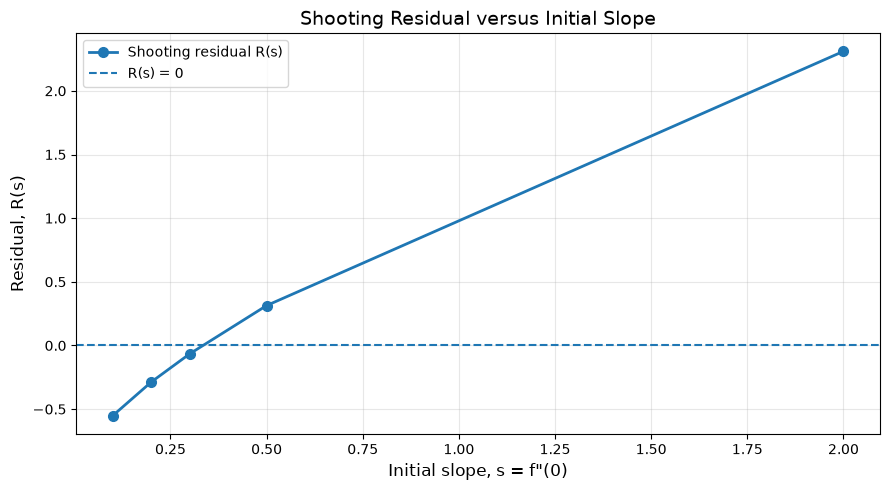

In [8]:
# CONVERTED 3rd ORDER BLAUSIUS TO FIRST-ORDER ODE

import numpy as np
import matplotlib.pyplot as plt

def first_order(u1, u2, u3):

    Y = np.array([u1, u2, u3])
    G = np.array([[0, 1, 0],[0, 0, 1],[0, 0, -u1/2]])
    Y_d = G @ Y

    return Y_d



# IMPLEMENTING RK3

def RK3(s, h, eta_inf):

    N = int(round(eta_inf / h))
    Y = np.zeros((N + 1, 3))
    eta = np.linspace(0, eta_inf, N + 1)

    Y[0, 0] = 0
    Y[0, 1] = 0
    Y[0, 2] = s

    for i in range(N):
        K1 = h * first_order(Y[i, 0], Y[i, 1], Y[i, 2])
        K2 = h * first_order(Y[i, 0] + K1[0]/2,Y[i, 1] + K1[1]/2,Y[i, 2] + K1[2]/2)
        K3 = h * first_order(Y[i, 0] - K1[0] + 2*K2[0],Y[i, 1] - K1[1] + 2*K2[1],Y[i, 2] - K1[2] + 2*K2[2])
        Y[i+1] = Y[i] + (K1 + 4*K2 + K3) / 6

    return eta, Y
    



# IMPLEMENTING SHOOTING METHOD TO FIND THAT RANGE

def shooting_error(s, eta_inf, h):

    eta, Y = RK3(s, h, eta_inf)
    fp_final = Y[-1, 1]
    residual = fp_final - 1.0

    return residual


eta_inf = 10
h = 0.01
s_values = np.array([0.1, 0.2, 0.3, 0.5, 2.0])
R_values = np.array([shooting_error(s, eta_inf, h) for s in s_values])


print("SHOOTING METHOD: RESIDUAL CALCULATIONS")
print("=" * 55)
print(f"{'Initial curvature (s)':<25}{'Residual R(s)':<20}")
print("-" * 55)

for s, R in zip(s_values, R_values):
    print(f"{s:<25.6f}{R:<20.10f}")

print("=" * 55)


plt.figure(figsize=(9, 5))
plt.plot(s_values,R_values,marker='o',linestyle='-',linewidth=2,markersize=7,label='Shooting residual R(s)')
plt.axhline(y=0,linestyle='--',linewidth=1.5,label='R(s) = 0')
plt.xlabel('Initial slope, s = f"(0)', fontsize=12)
plt.ylabel('Residual, R(s)', fontsize=12)
plt.title('Shooting Residual versus Initial Slope',fontsize=14)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()
